# Imports

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import os
from tqdm import tqdm
from utils.preprocessing import load_images_from_npy
from collections import Counter
import matplotlib.pyplot as plt
%matplotlib inline

# Utils

In [2]:
def get_age_values(df):
    age_values = set()
    for row in tqdm(df.itertuples()):
        context = eval(row.context)
        if "patient" in context and "age" in context["patient"]:
            age_values.add(context["patient"]["age"])

    return age_values

In [9]:
def get_base_stats(df, idx=0):
    sample_context = df.iloc[idx]["context"]
    sample_findings = df.iloc[idx]["findings"]

    print("Sample context:")
    print(sample_context)
    print("\nSample findings:")
    print(sample_findings)
    
    sample_img_path = os.path.join("..", df.iloc[idx]["exam"])
    sample_img = load_images_from_npy(sample_img_path)
    print("Image stats:")
    print(f"Shape: {sample_img.shape} | Max: {sample_img.max()} | Min: {sample_img.min()} | Dtype: {sample_img.dtype}")

    plt.imshow(sample_img, cmap='gray')
    plt.axis('off')
    plt.show()

In [20]:
import numpy as np


def compare_images(df, idxs=(0, 1)):
    img_paths = [os.path.join("..", df.iloc[idx]["exam"]) for idx in idxs]
    images = [load_images_from_npy(path) for path in img_paths]

    # compute distances between images
    distances = []
    for i in range(len(images)-1):
        for j in range(i+1, len(images)):
            diff = images[i]-images[j]
            distances.append((i, j, np.linalg.norm(diff)))

    print("Distances between images:")
    for i, j, dist in distances:
        print(f"Image {i} and Image {j}: {dist}")

    for i, img in enumerate(images):
        print(f"Image {idxs[i]} stats: Shape: {img.shape} | Max: {img.max()} | Min: {img.min()} | Dtype: {img.dtype}")
        plt.subplot(1, len(images), i+1)
        plt.imshow(img, cmap='gray')
        plt.title(f"Image {idxs[i]}")
        plt.axis('off')
    
    plt.show()

In [37]:
def check_not_present_lesions(df):
    for row in tqdm(df.itertuples()):
        findings = eval(row.findings)
        if ("lesion status" in findings) and (findings["lesion status"] == "not_present"):
            print(f"Lesion not present for index {row.Index}")
            print(f"Context: {row.context}")
            print(f"Findings: {row.findings}")
            print("-" * 50)

# Advanced Lesions MRI

In [30]:
dataset_name = "advanced-mri-breast-lesions"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [31]:
advanced_mri_breast_lesions_df = pd.read_csv(csv_path)
advanced_mri_breast_lesions_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,8bf78661-eaa2-447b-935d-adf7b437515e,advanced-mri-lesions-AMBL-001,advanced-mri-lesions,mri,(4) suspicious,unknown,GE MEDICAL SYSTEMS 1.5 T,../data/processed/advanced-mri-breast-lesions/...,"[""../data/processed/advanced-mri-breast-lesion...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",advanced-mri-lesions-AMBL-001,NaN,grounded,1
1,dbe55acb-3239-4371-826f-05fc59fdf141,advanced-mri-lesions-AMBL-001,advanced-mri-lesions,mri,(4) suspicious,unknown,GE MEDICAL SYSTEMS 1.5 T,../data/processed/advanced-mri-breast-lesions/...,"[""../data/processed/advanced-mri-breast-lesion...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",advanced-mri-lesions-AMBL-001,NaN,grounded,1
2,664202e3-5d45-42c8-9cd4-b1398fcdf386,advanced-mri-lesions-AMBL-001,advanced-mri-lesions,mri,(4) suspicious,unknown,GE MEDICAL SYSTEMS 1.5 T,../data/processed/advanced-mri-breast-lesions/...,"[""../data/processed/advanced-mri-breast-lesion...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",advanced-mri-lesions-AMBL-001,NaN,grounded,1
3,4676ec96-6b9a-44ef-bd67-3bb5738b3e3f,advanced-mri-lesions-AMBL-001,advanced-mri-lesions,mri,(4) suspicious,unknown,GE MEDICAL SYSTEMS 1.5 T,../data/processed/advanced-mri-breast-lesions/...,"[""../data/processed/advanced-mri-breast-lesion...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",advanced-mri-lesions-AMBL-001,NaN,grounded,1
4,b5aeb92e-fc2d-4b46-a0b4-110d20cd3f6d,advanced-mri-lesions-AMBL-001,advanced-mri-lesions,mri,(4) suspicious,unknown,GE MEDICAL SYSTEMS 1.5 T,../data/processed/advanced-mri-breast-lesions/...,"[""../data/processed/advanced-mri-breast-lesion...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",advanced-mri-lesions-AMBL-001,NaN,grounded,1


Sample context:
{"patient":{"age":"60-69","has implants":"no"},"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"pre-contrast"}}

Sample findings:
{"lesion status":"absent","assessment":{"birads":"(1) negative"}}
Image stats:
Shape: (560, 560) | Max: 64648 | Min: 0 | Dtype: uint16


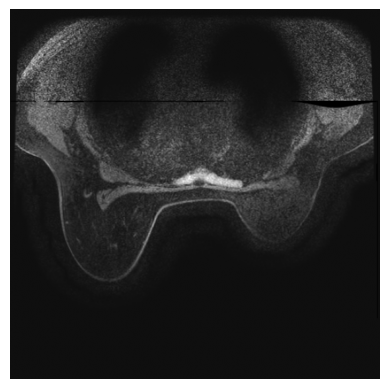

In [32]:
get_base_stats(advanced_mri_breast_lesions_df, 154)

Distances between images:
Image 0 and Image 1: 7180492.869414745
Image 0 and Image 2: 8474479.19026019
Image 0 and Image 3: 10886695.025138896
Image 0 and Image 4: 8826698.409376068
Image 0 and Image 5: 32551756.420987763
Image 1 and Image 2: 33663007.866092905
Image 1 and Image 3: 32770606.051249005
Image 1 and Image 4: 32796571.2220632
Image 1 and Image 5: 31083941.433274608
Image 2 and Image 3: 33696006.480144545
Image 2 and Image 4: 33097012.090087634
Image 2 and Image 5: 32522615.89264758
Image 3 and Image 4: 14696412.629521396
Image 3 and Image 5: 33012200.491335806
Image 4 and Image 5: 33255792.0657668
Image 0 stats: Shape: (560, 560) | Max: 64704 | Min: 0 | Dtype: uint16
Image 1 stats: Shape: (560, 560) | Max: 63940 | Min: 0 | Dtype: uint16
Image 2 stats: Shape: (560, 560) | Max: 61434 | Min: 0 | Dtype: uint16
Image 3 stats: Shape: (560, 560) | Max: 64696 | Min: 0 | Dtype: uint16
Image 4 stats: Shape: (560, 560) | Max: 63549 | Min: 0 | Dtype: uint16
Image 5 stats: Shape: (560, 

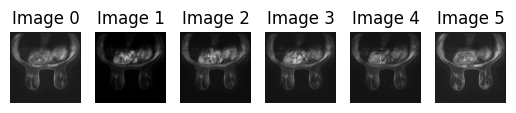

In [33]:
compare_images(advanced_mri_breast_lesions_df, idxs=(0, 1, 2, 3, 4, 5))

In [67]:
Counter(advanced_mri_breast_lesions_df["birads"])

Counter({'(5) highly suggestive of malignancy': 505,
         '(1) negative': 196,
         '(2) benign': 135,
         '(4) suspicious': 105,
         '(3) probably benign': 25})

# BUS-CoT

In [59]:
dataset_name = "BUSCoT"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [60]:
bus_cot_df = pd.read_csv(csv_path)
bus_cot_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,2486e201-6892-42f1-aa25-9dbc65b61143,bus-cot-budiat-BUDIAT@000001,bus-cot/budiat,ultrasound,(2) benign,unknown,unknown,../data/processed/BUSCoT/imgs/bus-cot-budiat-B...,NaN,"{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",bus-cot-budiat-BUDIAT@000001-000000,NaN,grounded,0
1,3f9efaad-d676-4ab7-9f01-b11aa5761883,bus-cot-budiat-BUDIAT@000002,bus-cot/budiat,ultrasound,(2) benign,unknown,unknown,../data/processed/BUSCoT/imgs/bus-cot-budiat-B...,NaN,"{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",bus-cot-budiat-BUDIAT@000002-000001,NaN,grounded,0
2,4e802ea5-ddc3-4c48-80a5-ef5327146774,bus-cot-budiat-BUDIAT@000003,bus-cot/budiat,ultrasound,(2) benign,unknown,unknown,../data/processed/BUSCoT/imgs/bus-cot-budiat-B...,NaN,"{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",bus-cot-budiat-BUDIAT@000003-000002,NaN,grounded,0
3,1a7e4eaf-6f49-4b03-abdc-200220f2b1c2,bus-cot-budiat-BUDIAT@000004,bus-cot/budiat,ultrasound,(2) benign,unknown,unknown,../data/processed/BUSCoT/imgs/bus-cot-budiat-B...,NaN,"{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",bus-cot-budiat-BUDIAT@000004-000003,NaN,grounded,0
4,e8791c24-9812-41be-9ac6-6094caa8fc27,bus-cot-budiat-BUDIAT@000005,bus-cot/budiat,ultrasound,(2) benign,unknown,unknown,../data/processed/BUSCoT/imgs/bus-cot-budiat-B...,NaN,"{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",bus-cot-budiat-BUDIAT@000005-000004,NaN,grounded,0


In [61]:
get_age_values(bus_cot_df)

0it [00:00, ?it/s]

6155it [00:00, 39270.48it/s]


set()

Sample context:
{"exam":{"modality":"ultrasound"}}

Sample findings:
{"lesion status":"present","annotation scope":"complete","lesions":[{"finding type":"mass","mass details":{"margin":"circumscribed","echo pattern":"hypoechoic"},"is index":true,"lesion id":"L1"}],"assessment":{"birads":"(3) probably benign"}}
Image stats:
Shape: (560, 672) | Max: 65126 | Min: 0 | Dtype: uint16


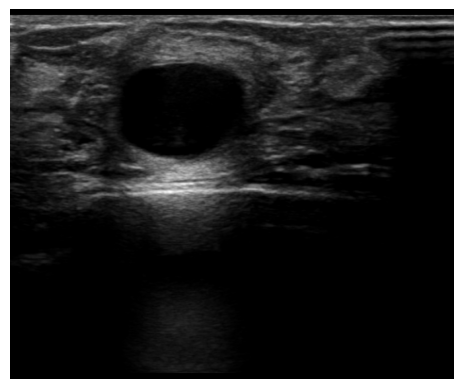

In [65]:
get_base_stats(bus_cot_df, 124)

In [48]:
check_not_present_lesions(bus_cot_df)

6155it [00:00, 31978.72it/s]


In [68]:
Counter(bus_cot_df["birads"])

Counter({'(4) suspicious': 3422,
         '(3) probably benign': 2095,
         '(2) benign': 331,
         '(5) highly suggestive of malignancy': 307})

# Breast Lesions USG


In [39]:
dataset_name = "breast-lesions-usg"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [40]:
breast_lesions_usg_df = pd.read_csv(csv_path)
breast_lesions_usg_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,bd980bcb-3a54-4ee9-80aa-91d27566be2b,breast-lesions-usg-1,breast-lesions-usg,ultrasound,(2) benign,unknown,unknown,../data/processed/breast-lesions-usg/imgs/brea...,"[""../data/processed/breast-lesions-usg/imgs/br...","{""patient"":{""age"":""50-59""},""exam"":{""modality"":...","{""breast"":{""tissue composition"":""heterogeneous...",breast-lesions-usg-1,NaN,grounded,1
1,d85eacf4-8743-478d-a89f-0c1d3494deda,breast-lesions-usg-2,breast-lesions-usg,ultrasound,(4) suspicious,unknown,unknown,../data/processed/breast-lesions-usg/imgs/brea...,"[""../data/processed/breast-lesions-usg/imgs/br...","{""exam"":{""modality"":""ultrasound""}}","{""breast"":{""tissue composition"":""homogeneous b...",breast-lesions-usg-2,NaN,grounded,1
2,f81ea565-79fb-4fb2-a5df-d1c8c8bfff4d,breast-lesions-usg-3,breast-lesions-usg,ultrasound,(4) suspicious,unknown,unknown,../data/processed/breast-lesions-usg/imgs/brea...,"[""../data/processed/breast-lesions-usg/imgs/br...","{""patient"":{""age"":""50-59""},""exam"":{""modality"":...","{""breast"":{""tissue composition"":""heterogeneous...",breast-lesions-usg-3,NaN,grounded,1
3,1b6a9634-7086-49c9-b1c8-c1b0568a6ec1,breast-lesions-usg-4,breast-lesions-usg,ultrasound,(3) probably benign,unknown,unknown,../data/processed/breast-lesions-usg/imgs/brea...,"[""../data/processed/breast-lesions-usg/imgs/br...","{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""tissue composition"":""homogeneous b...",breast-lesions-usg-4,NaN,grounded,1
4,0d95e0e7-b8db-40f6-a8e6-bfd8eb071ab3,breast-lesions-usg-5,breast-lesions-usg,ultrasound,(4) suspicious,unknown,unknown,../data/processed/breast-lesions-usg/imgs/brea...,"[""../data/processed/breast-lesions-usg/imgs/br...","{""patient"":{""age"":""60-69""},""exam"":{""modality"":...","{""breast"":{""tissue composition"":""homogeneous b...",breast-lesions-usg-5,NaN,grounded,1


In [41]:
get_age_values(breast_lesions_usg_df)

256it [00:00, 33302.58it/s]


{'40-49', '50-59', '60-69', '70-79', '80+', '<40'}

Sample context:
{"patient":{"age":"70-79"},"exam":{"modality":"ultrasound"}}

Sample findings:
{"breast":{"tissue composition":"heterogeneous background echotexture"},"lesion status":"present","annotation scope":"complete","lesions":[{"finding type":"mass","mass details":{"shape":"irregular","margin":"indistinct","echo pattern":"hypoechoic","posterior features":"shadowing"},"is index":true,"lesion id":"L1"}],"assessment":{"birads":"(4) suspicious"}}
Image stats:
Shape: (560, 672) | Max: 57983 | Min: 0 | Dtype: uint16


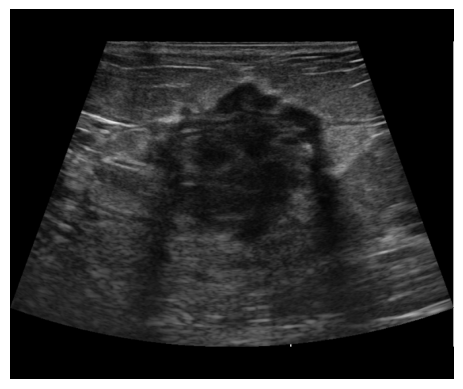

In [47]:
get_base_stats(breast_lesions_usg_df, 10)

In [29]:
check_not_present_lesions(breast_lesions_usg_df)

256it [00:00, 21603.16it/s]

Lesion not present for index 44
Context: {"patient":{"age":"<40"},"exam":{"modality":"ultrasound"}}
Findings: {"breast":{"tissue composition":"homogeneous background echotexture - fibroglandular"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 60
Context: {"exam":{"modality":"ultrasound"}}
Findings: {"breast":{"tissue composition":"homogeneous background echotexture - fibroglandular"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 208
Context: {"patient":{"age":"50-59"},"exam":{"modality":"ultrasound"}}
Findings: {"breast":{"tissue composition":"heterogeneous background echotexture"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 212
Context: {"patient":{"age":"60-69"},"exam":{"modality":"ultrasound"}}


In [69]:
Counter(breast_lesions_usg_df["birads"])

Counter({'(4) suspicious': 139,
         '(5) highly suggestive of malignancy': 46,
         '(3) probably benign': 37,
         '(2) benign': 30,
         '(1) negative': 4})

# Breast Micro Calcifications

In [48]:
dataset_name = "breast-micro-calc"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [49]:
breast_micro_calc_df = pd.read_csv(csv_path)
breast_micro_calc_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,6298dc4f-8fef-409a-ad12-52b37485a040,breast-micro-calc-Normal_cases_1,breast-micro-calc,mammography,(1) negative,unknown,unknown,../data/processed/breast-micro-calc/imgs/Norma...,NaN,"{""patient"":{""age"":""60-69""},""exam"":{""modality"":...","{""breast"":{""composition"":""(a) the breasts are ...",breast-micro-calc-Normal_cases_1,breast-micro-calc-Normal_cases_1-right,exam_level,0
1,94455642-08f3-4352-aea1-9cf42f163cfb,breast-micro-calc-Normal_cases_1,breast-micro-calc,mammography,(1) negative,unknown,unknown,../data/processed/breast-micro-calc/imgs/Norma...,NaN,"{""patient"":{""age"":""60-69""},""exam"":{""modality"":...","{""breast"":{""composition"":""(a) the breasts are ...",breast-micro-calc-Normal_cases_1,breast-micro-calc-Normal_cases_1-right,exam_level,0
2,dc78c4be-7ca1-4265-abd6-ff159393d3e5,breast-micro-calc-Normal_cases_2,breast-micro-calc,mammography,(2) benign,unknown,unknown,../data/processed/breast-micro-calc/imgs/Norma...,NaN,"{""patient"":{""age"":""60-69""},""exam"":{""modality"":...","{""breast"":{""composition"":""(c) the breasts are ...",breast-micro-calc-Normal_cases_2,breast-micro-calc-Normal_cases_2-right,exam_level,0
3,5b2a6290-cb7a-45bc-8b97-836b19f0c22a,breast-micro-calc-Normal_cases_2,breast-micro-calc,mammography,(2) benign,unknown,unknown,../data/processed/breast-micro-calc/imgs/Norma...,NaN,"{""patient"":{""age"":""60-69""},""exam"":{""modality"":...","{""breast"":{""composition"":""(c) the breasts are ...",breast-micro-calc-Normal_cases_2,breast-micro-calc-Normal_cases_2-right,exam_level,0
4,b628fa89-ad41-4f68-9a9a-a96ac6c4de44,breast-micro-calc-Normal_cases_3,breast-micro-calc,mammography,(1) negative,unknown,unknown,../data/processed/breast-micro-calc/imgs/Norma...,NaN,"{""patient"":{""age"":""60-69""},""exam"":{""modality"":...","{""breast"":{""composition"":""(b) there are scatte...",breast-micro-calc-Normal_cases_3,breast-micro-calc-Normal_cases_3-right,exam_level,0


In [50]:
# get all possible values for age in the context
get_age_values(breast_micro_calc_df)

200it [00:00, 23891.68it/s]


{'40-49', '50-59', '60-69', '70-79', '80+', '<40'}

Sample context:
{"patient":{"age":"50-59"},"exam":{"modality":"mammography","laterality":"right","view":"cranial caudal"}}

Sample findings:
{"breast":{"composition":"(c) the breasts are heterogeneously dense, which may obscure small masses"},"lesion status":"present","annotation scope":"index_only","lesions":[{"finding type":"calcification","is index":true,"lesion id":"L1"}],"assessment":{"birads":"(4a) suspicious - low suspicion for malignancy"}}
Image stats:
Shape: (1120, 784) | Max: 65535 | Min: 0 | Dtype: uint16


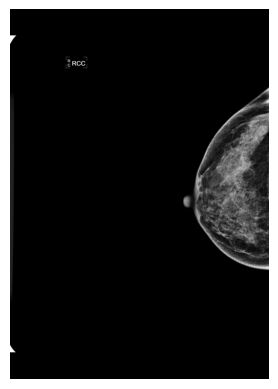

In [58]:
get_base_stats(breast_micro_calc_df, 124)

In [38]:
check_not_present_lesions(breast_micro_calc_df)

200it [00:00, 28601.75it/s]

Lesion not present for index 0
Context: {"patient":{"age":"60-69"},"exam":{"modality":"mammography","laterality":"right","view":"cranial caudal"}}
Findings: {"breast":{"density":"(a) the breasts are almost entirely fatty"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 1
Context: {"patient":{"age":"60-69"},"exam":{"modality":"mammography","laterality":"right","view":"mediolateral oblique"}}
Findings: {"breast":{"density":"(a) the breasts are almost entirely fatty"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 4
Context: {"patient":{"age":"60-69"},"exam":{"modality":"mammography","laterality":"right","view":"cranial caudal"}}
Findings: {"breast":{"density":"(b) there are scattered areas of fibroglandular density"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------

Distances between images:
Image 0 and Image 1: 14274202.98066943
Image 0 stats: Shape: (1120, 784) | Max: 65535 | Min: 0 | Dtype: uint16
Image 10 stats: Shape: (1120, 784) | Max: 65535 | Min: 0 | Dtype: uint16


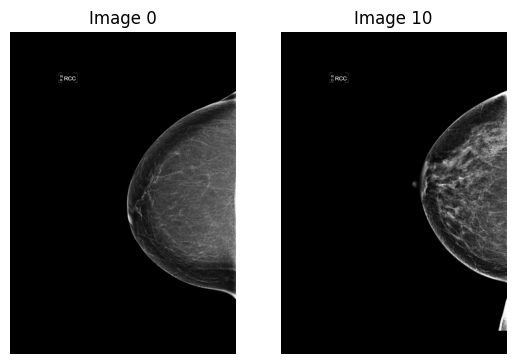

In [70]:
compare_images(breast_micro_calc_df, idxs=(0, 10))

In [71]:
Counter(breast_micro_calc_df["birads"])

Counter({'(2) benign': 56,
         '(4a) suspicious - low suspicion for malignancy': 54,
         '(1) negative': 44,
         '(4b) suspicious - moderate suspicion for malignancy': 30,
         '(4c) suspicious - high suspicion for malignancy': 12,
         '(5) highly suggestive of malignancy': 4})

# CBIS-DDSM

In [144]:
dataset_name = "cbis-ddsm"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [145]:
cbis_ddsm_df = pd.read_csv(csv_path)
cbis_ddsm_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings
0,c3b540b1-ac22-4777-b3ff-c00582f4e9cd,cbis-ddsm-P_00038,cbis-ddsm,mammography,(4) suspicious,unknown,unknown,../data/processed/cbis-ddsm/imgs/P_00038-c3b54...,['../data/processed/cbis-ddsm/imgs/P_00038-c3b...,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""density"":""(b) there are scattered ..."
1,f4c0c52c-f0ef-4fa2-b56d-e939b6ac8bad,cbis-ddsm-P_00038,cbis-ddsm,mammography,(4) suspicious,unknown,unknown,../data/processed/cbis-ddsm/imgs/P_00038-f4c0c...,['../data/processed/cbis-ddsm/imgs/P_00038-f4c...,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""density"":""(b) there are scattered ..."
2,d19d0acc-7868-4ad3-9788-7e0be958048e,cbis-ddsm-P_00038,cbis-ddsm,mammography,(2) benign,unknown,unknown,../data/processed/cbis-ddsm/imgs/P_00038-d19d0...,['../data/processed/cbis-ddsm/imgs/P_00038-d19...,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""density"":""(b) there are scattered ..."
3,4f0a9864-24a8-4bc9-9ec6-11dbedc2ba2d,cbis-ddsm-P_00038,cbis-ddsm,mammography,(2) benign,unknown,unknown,../data/processed/cbis-ddsm/imgs/P_00038-4f0a9...,['../data/processed/cbis-ddsm/imgs/P_00038-4f0...,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""density"":""(b) there are scattered ..."
4,18dd8bec-7f8b-46db-999d-3564d7790664,cbis-ddsm-P_00041,cbis-ddsm,mammography,(2) benign,unknown,unknown,../data/processed/cbis-ddsm/imgs/P_00041-18dd8...,['../data/processed/cbis-ddsm/imgs/P_00041-18d...,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""density"":""(a) the breasts are almo..."


In [146]:
get_age_values(cbis_ddsm_df)

2865it [00:00, 38192.81it/s]


set()

Sample context:
{"exam":{"modality":"mammography","laterality":"right","view":"cranial caudal"}}

Sample findings:
{"breast":{"density":"(c) the breasts are heterogeneously dense, which may obscure small masses"},"lesion":{"location":{"laterality":"right"},"type":"calcification","calcification details":{"type":"suspicious morphology","type details":"fine pleomorphic","distribution":"linear"}},"assessment":{"birads":"(4) suspicious"}}
Image stats:
Shape: (1, 512, 512) | Max: 65535 | Min: 0 | Dtype: uint16


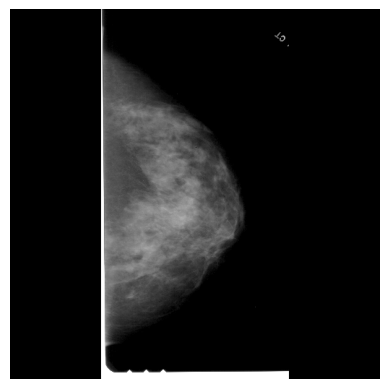

In [153]:
get_base_stats(cbis_ddsm_df, 124)

Distances between images:
Image 0 and Image 1: 14436690.74209817
Image 0 stats: Shape: (1, 512, 512) | Max: 56562 | Min: 0 | Dtype: uint16
Image 1 stats: Shape: (1, 512, 512) | Max: 65535 | Min: 0 | Dtype: uint16


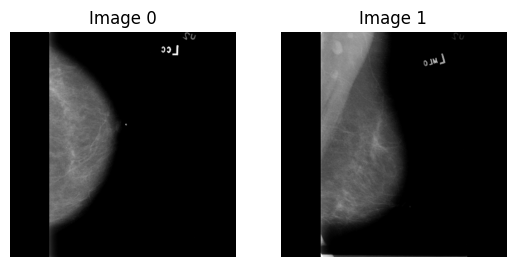

In [72]:
compare_images(cbis_ddsm_df, idxs=(0, 1))

In [73]:
check_not_present_lesions(cbis_ddsm_df)

2865it [00:00, 23749.70it/s]


In [74]:
Counter(cbis_ddsm_df["birads"])

Counter({'(4) suspicious': 1543,
         '(5) highly suggestive of malignancy': 540,
         '(3) probably benign': 423,
         '(2) benign': 356,
         '(1) negative': 3})

# Tompei CMMD

In [94]:
dataset_name = "tompei-cmmd"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [95]:
tompei_cmmd_df = pd.read_csv(csv_path)
tompei_cmmd_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,6130c320-310a-4206-b418-26609a72cae4,tompei-cmmd-D1-0001,tompei-cmmd,mammography,(2) benign,asian,GE Senographe DS mammography system,../data/processed/tompei-cmmd/imgs/D1-0001-613...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(c) the breasts are ...",tompei-cmmd-D1-0001,tompei-cmmd-D1-0001-right,exam_level,0
1,05bc4131-4ffd-4230-a396-2377f9f8ae85,tompei-cmmd-D1-0001,tompei-cmmd,mammography,(2) benign,asian,GE Senographe DS mammography system,../data/processed/tompei-cmmd/imgs/D1-0001-05b...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(c) the breasts are ...",tompei-cmmd-D1-0001,tompei-cmmd-D1-0001-right,exam_level,0
2,ed44ba3f-ef79-48a1-9f6b-9dc422b60414,tompei-cmmd-D1-0002,tompei-cmmd,mammography,(2) benign,asian,GE Senographe DS mammography system,../data/processed/tompei-cmmd/imgs/D1-0002-ed4...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(c) the breasts are ...",tompei-cmmd-D1-0002,tompei-cmmd-D1-0002-left,exam_level,0
3,b077c9b4-9fab-4fbf-81bc-dbc76b2f5d0e,tompei-cmmd-D1-0002,tompei-cmmd,mammography,(2) benign,asian,GE Senographe DS mammography system,../data/processed/tompei-cmmd/imgs/D1-0002-b07...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(c) the breasts are ...",tompei-cmmd-D1-0002,tompei-cmmd-D1-0002-left,exam_level,0
4,307db6d4-3fd7-4c62-b8b0-629ef88d3e80,tompei-cmmd-D1-0003,tompei-cmmd,mammography,(3) probably benign,asian,GE Senographe DS mammography system,../data/processed/tompei-cmmd/imgs/D1-0003-307...,NaN,"{""patient"":{""age"":""<40""},""exam"":{""modality"":""m...","{""breast"":{""composition"":""(b) there are scatte...",tompei-cmmd-D1-0003,tompei-cmmd-D1-0003-left,exam_level,0


In [96]:
get_age_values(tompei_cmmd_df)

1286it [00:00, 26445.36it/s]


{'40-49', '50-59', '60-69', '70-79', '80+', '<40'}

Sample context:
{"patient":{"age":"50-59"},"exam":{"modality":"mammography","laterality":"right","view":"mediolateral oblique"}}

Sample findings:
{"breast":{"composition":"(b) there are scattered areas of fibroglandular density"},"lesion status":"present","annotation scope":"complete","lesions":[{"finding type":"calcification","location":{"laterality":"right","coarse location":"medial"},"calcification details":{"type":"typically benign","type details":"round","distribution":"regional"},"is index":true,"lesion id":"L1"}],"assessment":{"birads":"(2) benign"}}
Image stats:
Shape: (1120, 784) | Max: 64616 | Min: 0 | Dtype: uint16


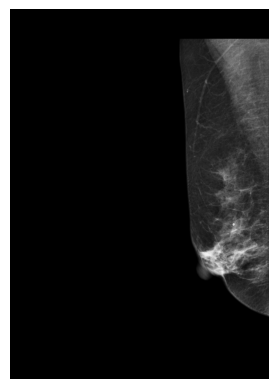

In [97]:
get_base_stats(tompei_cmmd_df, 55)

In [89]:
check_not_present_lesions(tompei_cmmd_df)

1286it [00:00, 22639.75it/s]

Lesion not present for index 668
Context: {"patient":{"age":"40-49"},"exam":{"modality":"mammography","laterality":"left","view":"cranial caudal"}}
Findings: {"breast":{"density":"(c) the breasts are heterogeneously dense, which may obscure small masses"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 669
Context: {"patient":{"age":"40-49"},"exam":{"modality":"mammography","laterality":"left","view":"mediolateral oblique"}}
Findings: {"breast":{"density":"(c) the breasts are heterogeneously dense, which may obscure small masses"},"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------


In [97]:
Counter(tompei_cmmd_df["birads"])

Counter({'(5) highly suggestive of malignancy': 504,
         '(4) suspicious': 338,
         '(3) probably benign': 322,
         '(2) benign': 120,
         '(1) negative': 2})

# OASBUD

In [72]:
dataset_name = "oasbud"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [73]:
oasbud_df = pd.read_csv(csv_path)
oasbud_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,09fd94f3-1a27-4901-8055-d49f5f3996d4,oasbud-1mm,oasbud,ultrasound,(3) probably benign,unknown,unknown,../data/processed/oasbud/imgs/oasbud-1mm-09fd9...,"[""../data/processed/oasbud/imgs/oasbud-1mm-09f...","{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",oasbud-1mm,NaN,grounded,1
1,3e4ea6fd-a5d2-4f68-96c5-efc50d98bbb9,oasbud-1mm,oasbud,ultrasound,(3) probably benign,unknown,unknown,../data/processed/oasbud/imgs/oasbud-1mm-3e4ea...,"[""../data/processed/oasbud/imgs/oasbud-1mm-3e4...","{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",oasbud-1mm,NaN,grounded,1
2,26b4ae22-40d6-4189-815b-c8c11dc9a9ee,oasbud-2mm,oasbud,ultrasound,(3) probably benign,unknown,unknown,../data/processed/oasbud/imgs/oasbud-2mm-26b4a...,"[""../data/processed/oasbud/imgs/oasbud-2mm-26b...","{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",oasbud-2mm,NaN,grounded,1
3,3f01fd0c-04e2-4f38-b86b-df1447e76281,oasbud-2mm,oasbud,ultrasound,(3) probably benign,unknown,unknown,../data/processed/oasbud/imgs/oasbud-2mm-3f01f...,"[""../data/processed/oasbud/imgs/oasbud-2mm-3f0...","{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",oasbud-2mm,NaN,grounded,1
4,b32a8cc7-8cea-42ed-8b81-046f263076fe,oasbud-3als,oasbud,ultrasound,(4) suspicious,unknown,unknown,../data/processed/oasbud/imgs/oasbud-3als-b32a...,"[""../data/processed/oasbud/imgs/oasbud-3als-b3...","{""exam"":{""modality"":""ultrasound""}}","{""lesion status"":""present"",""annotation scope"":...",oasbud-3als,NaN,grounded,1


Sample context:
{"exam":{"modality":"ultrasound"}}

Sample findings:
{"lesion status":"present","annotation scope":"complete","assessment":{"birads":"(5) highly suggestive of malignancy"}}
Image stats:
Shape: (560, 672) | Max: 61157 | Min: 0 | Dtype: uint16


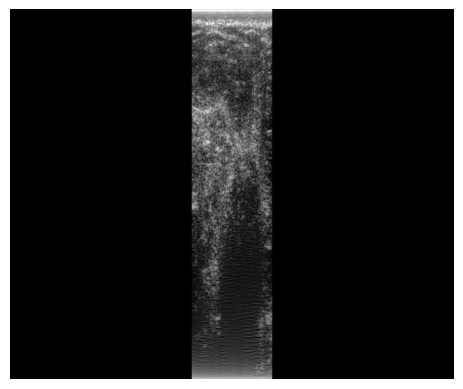

In [81]:
get_base_stats(oasbud_df, 10)

In [82]:
check_not_present_lesions(oasbud_df)

200it [00:00, 32584.71it/s]


In [83]:
Counter(oasbud_df["birads"])

Counter({'(4) suspicious': 88,
         '(3) probably benign': 62,
         '(5) highly suggestive of malignancy': 50})

# LA Breast

In [98]:
dataset_name = "la-breast"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [99]:
la_breast_df = pd.read_csv(csv_path)
la_breast_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,cc640330-c679-40a7-91c1-1560c5b6c139,la-breast-Breast_Mri_10,la-breast,mri,(5) highly suggestive of malignancy,unknown,Multiple 1.5T scanners,../data/processed/la-breast/imgs/la-breast-Bre...,"[""../data/processed/la-breast/imgs/la-breast-B...","{""exam"":{""modality"":""mri"",""laterality"":""bilate...","{""breast"":{""fgt"":""(d) extreme fibroglandular t...",la-breast-Breast_Mri_10,NaN,grounded,1
1,8ca1544d-7e65-4da2-b572-5f6819c9a3eb,la-breast-Breast_Mri_10,la-breast,mri,(5) highly suggestive of malignancy,unknown,Multiple 1.5T scanners,../data/processed/la-breast/imgs/la-breast-Bre...,"[""../data/processed/la-breast/imgs/la-breast-B...","{""exam"":{""modality"":""mri"",""laterality"":""bilate...","{""breast"":{""fgt"":""(d) extreme fibroglandular t...",la-breast-Breast_Mri_10,NaN,grounded,1
2,d99b3da0-3149-419a-a4e9-02652eb4d0ac,la-breast-Breast_Mri_10,la-breast,mri,(5) highly suggestive of malignancy,unknown,Multiple 1.5T scanners,../data/processed/la-breast/imgs/la-breast-Bre...,"[""../data/processed/la-breast/imgs/la-breast-B...","{""exam"":{""modality"":""mri"",""laterality"":""bilate...","{""breast"":{""fgt"":""(d) extreme fibroglandular t...",la-breast-Breast_Mri_10,NaN,grounded,1
3,430a9ffa-6db5-402c-bae4-b27704bd28bd,la-breast-Breast_Mri_10,la-breast,mri,(5) highly suggestive of malignancy,unknown,Multiple 1.5T scanners,../data/processed/la-breast/imgs/la-breast-Bre...,"[""../data/processed/la-breast/imgs/la-breast-B...","{""exam"":{""modality"":""mri"",""laterality"":""bilate...","{""breast"":{""fgt"":""(d) extreme fibroglandular t...",la-breast-Breast_Mri_10,NaN,grounded,1
4,6bea2a7c-2bb7-4958-9e10-d9b031d557e2,la-breast-Breast_Mri_10,la-breast,mri,(5) highly suggestive of malignancy,unknown,Multiple 1.5T scanners,../data/processed/la-breast/imgs/la-breast-Bre...,"[""../data/processed/la-breast/imgs/la-breast-B...","{""exam"":{""modality"":""mri"",""laterality"":""bilate...","{""breast"":{""fgt"":""(d) extreme fibroglandular t...",la-breast-Breast_Mri_10,NaN,grounded,1


In [100]:
get_age_values(la_breast_df)

868it [00:00, 32374.34it/s]


set()

Sample context:
{"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"post-contrast phase 1"}}

Sample findings:
{"breast":{"fgt":"(d) extreme fibroglandular tissue"},"lesion status":"present","annotation scope":"unknown","assessment":{"birads":"(5) highly suggestive of malignancy"}}
Image stats:
Shape: (560, 560) | Max: 64937 | Min: 0 | Dtype: uint16


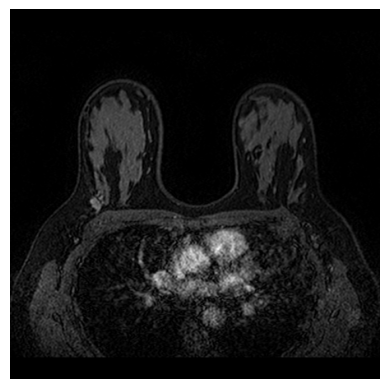

In [103]:
get_base_stats(la_breast_df, 1)

Distances between images:
Image 0 and Image 1: 15669120.493202068
Image 0 stats: Shape: (1, 512, 512) | Max: 64102 | Min: 0 | Dtype: uint16
Image 1 stats: Shape: (1, 512, 512) | Max: 63889 | Min: 0 | Dtype: uint16


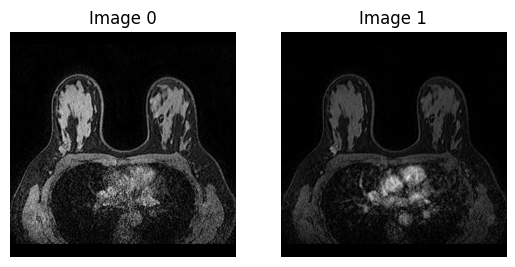

In [141]:
compare_images(la_breast_df, idxs=(0, 1))

In [142]:
check_not_present_lesions(la_breast_df)

868it [00:00, 32773.31it/s]

Lesion not present for index 18
Context: {"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"pre-contrast"}}
Findings: {"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 19
Context: {"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"post-contrast phase 1"}}
Findings: {"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 20
Context: {"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"post-contrast phase 2"}}
Findings: {"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------------------------------------
Lesion not present for index 21
Context: {"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"post-contrast phase 3"}}
Findings: {"lesion":"not_present","assessment":{"birads":"(1) negative"}}
--------------------

In [143]:
Counter(la_breast_df["birads"])

Counter({'(2) benign': 461,
         '(5) highly suggestive of malignancy': 269,
         '(1) negative': 120,
         '(3) probably benign': 12,
         '(4) suspicious': 6})

# INBreast

In [84]:
dataset_name = "inbreast"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [85]:
inbreast_df = pd.read_csv(csv_path)
inbreast_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,8220aed0-a2ee-4fe7-be25-880ad5d0006c,inbreast-61b13c59bcba149e,inbreast,mammography,(1) negative,unknown,unknown,../data/processed/inbreast/imgs/inbreast-61b13...,NaN,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""composition"":""(d) the breasts are ...",inbreast-61b13c59bcba149e,inbreast-61b13c59bcba149e-right,grounded,0
1,72b523f0-55e5-4da2-b7a7-373a04da0246,inbreast-61b13c59bcba149e,inbreast,mammography,(3) probably benign,unknown,unknown,../data/processed/inbreast/imgs/inbreast-61b13...,"[""../data/processed/inbreast/imgs/inbreast-61b...","{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""composition"":""(d) the breasts are ...",inbreast-61b13c59bcba149e,inbreast-61b13c59bcba149e-left,grounded,1
2,0f09f173-60d8-438f-8906-f1ec600b9c9d,inbreast-61b13c59bcba149e,inbreast,mammography,(1) negative,unknown,unknown,../data/processed/inbreast/imgs/inbreast-61b13...,NaN,"{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""composition"":""(d) the breasts are ...",inbreast-61b13c59bcba149e,inbreast-61b13c59bcba149e-right,grounded,0
3,de90843c-d9c4-4931-8941-63fee920096f,inbreast-61b13c59bcba149e,inbreast,mammography,(3) probably benign,unknown,unknown,../data/processed/inbreast/imgs/inbreast-61b13...,"[""../data/processed/inbreast/imgs/inbreast-61b...","{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""composition"":""(d) the breasts are ...",inbreast-61b13c59bcba149e,inbreast-61b13c59bcba149e-left,grounded,1
4,f09c21b2-176f-4c5e-a80f-d072fb93508a,inbreast-97ec8cadfca70d32,inbreast,mammography,(2) benign,unknown,unknown,../data/processed/inbreast/imgs/inbreast-97ec8...,"[""../data/processed/inbreast/imgs/inbreast-97e...","{""exam"":{""modality"":""mammography"",""laterality""...","{""breast"":{""composition"":""(c) the breasts are ...",inbreast-97ec8cadfca70d32,inbreast-97ec8cadfca70d32-left,grounded,1


Sample context:
{"exam":{"modality":"mammography","laterality":"right","view":"mediolateral oblique"}}

Sample findings:
{"breast":{"composition":"(c) the breasts are heterogeneously dense, which may obscure small masses"},"lesion status":"present","annotation scope":"index_only","lesions":[{"finding type":"calcification","is index":true,"lesion id":"L1"}],"assessment":{"birads":"(2) benign"}}
Image stats:
Shape: (1120, 784) | Max: 63881 | Min: 0 | Dtype: uint16


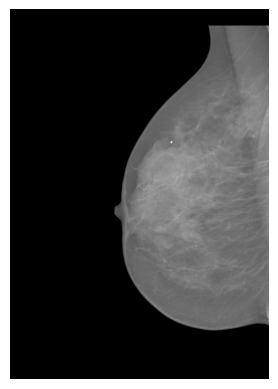

In [90]:
get_base_stats(inbreast_df, 12)

In [91]:
get_age_values(inbreast_df)

313it [00:00, 30889.09it/s]


set()

In [92]:
check_not_present_lesions(inbreast_df)

1it [00:00, 3410.00it/s]


NameError: name 'true' is not defined

In [93]:
Counter(inbreast_df["birads"])

Counter({'(2) benign': 192,
         '(1) negative': 67,
         '(3) probably benign': 21,
         '(4c) suspicious - high suspicion for malignancy': 12,
         '(4b) suspicious - moderate suspicion for malignancy': 8,
         '(5) highly suggestive of malignancy': 7,
         '(4a) suspicious - low suspicion for malignancy': 6})

# MAMMA MIA

In [104]:
dataset_name = "mama-mia"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [105]:
mamma_mia_df = pd.read_csv(csv_path)
mamma_mia_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,4e82f376-cbb1-4075-bc55-5769db77be34,mama-mia-DUKE_001,mama-mia/duke,mri,(5) highly suggestive of malignancy,black,SIEMENS Avanto,../data/processed/mama-mia/imgs/mama-mia-DUKE_...,"[""../data/processed/mama-mia/imgs/mama-mia-DUK...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",mama-mia-DUKE_001,NaN,grounded,1
1,1ba52814-341c-4cfa-8011-d40056a7d2ae,mama-mia-DUKE_001,mama-mia/duke,mri,(1) negative,black,SIEMENS Avanto,../data/processed/mama-mia/imgs/mama-mia-DUKE_...,NaN,"{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""absent"",""assessment"":{""birad...",mama-mia-DUKE_001,NaN,derived,0
2,7803b676-95b2-455c-93ba-b9af6902c346,mama-mia-DUKE_001,mama-mia/duke,mri,(1) negative,black,SIEMENS Avanto,../data/processed/mama-mia/imgs/mama-mia-DUKE_...,NaN,"{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""absent"",""assessment"":{""birad...",mama-mia-DUKE_001,NaN,derived,0
3,1ec06de8-b020-4698-b246-1f954fd934bc,mama-mia-DUKE_001,mama-mia/duke,mri,(5) highly suggestive of malignancy,black,SIEMENS Avanto,../data/processed/mama-mia/imgs/mama-mia-DUKE_...,"[""../data/processed/mama-mia/imgs/mama-mia-DUK...","{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""present"",""annotation scope"":...",mama-mia-DUKE_001,NaN,grounded,1
4,910164e4-a77e-45a1-a921-2e51f40ea61c,mama-mia-DUKE_001,mama-mia/duke,mri,(1) negative,black,SIEMENS Avanto,../data/processed/mama-mia/imgs/mama-mia-DUKE_...,NaN,"{""patient"":{""age"":""40-49"",""has implants"":""no""}...","{""lesion status"":""absent"",""assessment"":{""birad...",mama-mia-DUKE_001,NaN,derived,0


In [106]:
get_age_values(mamma_mia_df)

17575it [00:00, 29306.90it/s]


{'40-49', '50-59', '60-69', '70-79', '<40'}

Sample context:
{"patient":{"age":"<40","has implants":"no"},"exam":{"modality":"mri","laterality":"bilateral","contrast phase":"post-contrast phase 4"}}

Sample findings:
{"breast":{"fgt":"(d) extreme fibroglandular tissue"},"lesion status":"present","annotation scope":"complete","assessment":{"birads":"(5) highly suggestive of malignancy"}}
Image stats:
Shape: (560, 560) | Max: 37606 | Min: 0 | Dtype: uint16


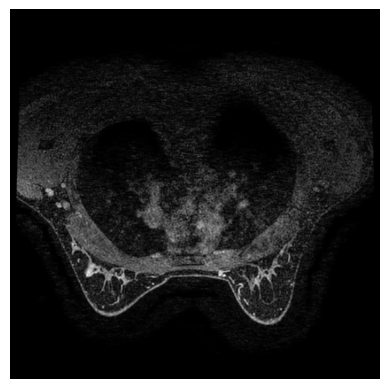

In [117]:
get_base_stats(mamma_mia_df, 1243)

In [ ]:
compare_images(mamma_mia_df, idxs=(0, 1))

In [ ]:
check_not_present_lesions(mamma_mia_df)

# EMBED

In [118]:
dataset_name = "embed"
csv_path = f"../../data/processed/{dataset_name}/{dataset_name}.csv"
imgs_path = f"../../data/processed/{dataset_name}/imgs/"

In [119]:
embed_df = pd.read_csv(csv_path)
embed_df.head(5)

,id,patient,dataset,modality,birads,race,machine,exam,segmentation,context,findings,exam_id,breast_id,assessment_scope,n_segmentations
0,324f8f09-c821-4b61-996c-6e9ca2aedabe,embed-10019048,embed,mammography,(2) benign,native hawaiian,GE MEDICAL SYSTEMS Senograph 2000D ADS_17.5,../data/processed/embed/imgs/10019048-324f8f09...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(d) the breasts are ...",embed-9608928385413377,embed-9608928385413377-left,grounded,0
1,0ad98900-faf4-49a3-81c0-b35aa7dcf376,embed-10019048,embed,mammography,(2) benign,native hawaiian,GE MEDICAL SYSTEMS Senograph 2000D ADS_17.5,../data/processed/embed/imgs/10019048-0ad98900...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(d) the breasts are ...",embed-9608928385413377,embed-9608928385413377-right,grounded,0
2,44ee1491-fcd2-4a0f-acdf-9250bc6b679c,embed-10019048,embed,mammography,(2) benign,native hawaiian,GE MEDICAL SYSTEMS Senograph 2000D ADS_17.5,../data/processed/embed/imgs/10019048-44ee1491...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(d) the breasts are ...",embed-9608928385413377,embed-9608928385413377-right,grounded,0
3,6aa7a07e-d035-44c8-adb6-a683e6e9822c,embed-10019048,embed,mammography,(2) benign,native hawaiian,GE MEDICAL SYSTEMS Senograph 2000D ADS_17.5,../data/processed/embed/imgs/10019048-6aa7a07e...,NaN,"{""patient"":{""age"":""40-49""},""exam"":{""modality"":...","{""breast"":{""composition"":""(d) the breasts are ...",embed-9608928385413377,embed-9608928385413377-left,grounded,0
4,67c20258-602c-4219-8ba8-349060139ca5,embed-10023113,embed,mammography,(1) negative,black,"HOLOGIC, Inc. Selenia Dimensions",../data/processed/embed/imgs/10023113-67c20258...,NaN,"{""patient"":{""age"":""50-59""},""exam"":{""modality"":...","{""breast"":{""composition"":""(b) there are scatte...",embed-9560054303330614,embed-9560054303330614-left,grounded,0


In [120]:
get_age_values(embed_df)

0it [00:00, ?it/s]

54805it [00:01, 30149.03it/s]


{'40-49', '50-59', '60-69', '70-79', '80+', '<40'}

In [121]:
embed_df[embed_df["patient"] == "embed-52662124"].index.tolist()

[25588,
 25589,
 25590,
 25591,
 25592,
 25593,
 25594,
 25595,
 25596,
 25597,
 25598,
 25599,
 25600,
 25601,
 25602,
 25603,
 25604,
 25605,
 25606,
 25607,
 25608,
 25609,
 25610,
 25611,
 25612,
 25613,
 25614,
 25615,
 25616,
 25617]

In [122]:
for elem in embed_df[embed_df["patient"] == "embed-25589"].index.tolist():
    for elem2 in embed_df[embed_df["patient"] == "embed-25589"].index.tolist():
        if elem == elem2:
            continue
        sample_img_path = os.path.join("..", embed_df.iloc[elem]["exam"])
        sample_img = load_images_from_npy(sample_img_path)

        sample2_path = os.path.join("..", embed_df.iloc[elem2]["exam"])
        sample2 = load_images_from_npy(sample2_path)

        if (sample_img == sample2).all():
            print(f"Found identical images at indices {elem} and {elem2}")

Sample context:
{"patient":{"age":"40-49"},"exam":{"modality":"mammography","laterality":"left","view":"mediolateral oblique"}}

Sample findings:
{"breast":{"composition":"(d) the breasts are extremely dense, which lowers the sensitivity of mammography"},"lesion status":"present","annotation scope":"complete","lesions":[{"location":{"laterality":"left","special location":"axillary tail"},"is index":true,"lesion id":"L1"}],"assessment":{"birads":"(2) benign"}}
Image stats:
Shape: (1120, 784) | Max: 64611 | Min: 0 | Dtype: uint16


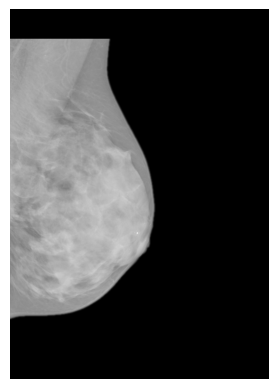

In [124]:
get_base_stats(embed_df, 0)

Sample context:
{"patient":{"age":"40-49"},"exam":{"modality":"mammography","laterality":"left","view":"mediolateral oblique"}}

Sample findings:
{"breast":{"composition":"(c) the breasts are heterogeneously dense, which may obscure small masses"},"lesion status":"present","annotation scope":"complete","lesions":[{"finding type":"calcification","location":{"laterality":"left"},"calcification details":{"type":"typically benign","type details":"round","distribution":"diffuse"},"is index":true,"lesion id":"L1"}],"assessment":{"birads":"(2) benign"}}
Image stats:
Shape: (1120, 784) | Max: 65535 | Min: 0 | Dtype: uint16


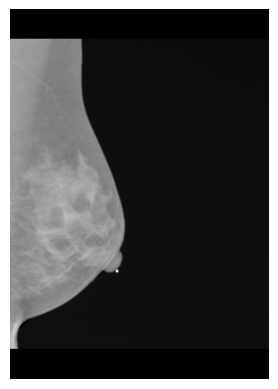

In [125]:
get_base_stats(embed_df, 1251)

In [126]:
Counter(embed_df["birads"])

Counter({'(2) benign': 31068,
         '(1) negative': 10908,
         '(3) probably benign': 9168,
         '(4) suspicious': 2662,
         '(5) highly suggestive of malignancy': 999})